Setup (same loading and event_id as Task_2-.ipynb)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def load(name):
    df = pd.read_pickle(f"MicroBooNE_data/{name}")
    obj_cols = df.columns[df.dtypes == object]
    df[obj_cols] = df[obj_cols].astype("float32")   # numeric columns stored as generic objects
    if "Subevent" in df:
        df["event_id"] = (df["Subevent"] == 0).cumsum()   # rows from one event share an id
    return df

sim = load("Simulation.pkl")

CAT = "Simulation category"
WGT = "Simulation weight"
ENERGY = "Total energy"
SIGNAL = 21

Preselection (same as Task_2-.ipynb)

In [2]:
valid = sim[ENERGY] < 100
pre = sim[valid].reset_index(drop=True)

sig_all = sim.loc[sim[CAT] == SIGNAL, WGT].sum()
sig_pre = pre.loc[pre[CAT] == SIGNAL, WGT].sum()
print(f"Events kept: {valid.mean(): .1%}")
print(f"Signal kept: {sig_pre / sig_all: .1%}")

Events kept:  27.1%
Signal kept:  46.8%


Rows per sub-event, before and after preselection

In [3]:
print(pd.DataFrame({"all": sim["Subevent"].value_counts(),
                    "preselected": pre["Subevent"].value_counts()}).fillna(0).astype(int).sort_index())

             all  preselected
Subevent                     
0         330851        88349
1         148439        41710
2          52998        14152
3          16502         4389
4           4857         1264
5           1369          362
6            410          100
7            125           28
8             46            7
9             12            2
10             7            2
11             4            0
12             1            0
13             1            0
14             1            0
15             1            0


Track length and PID LLh, all sub-events overlaid and each normalised to unit area (so the shapes can be compared regardless of how many rows each sub-event has)


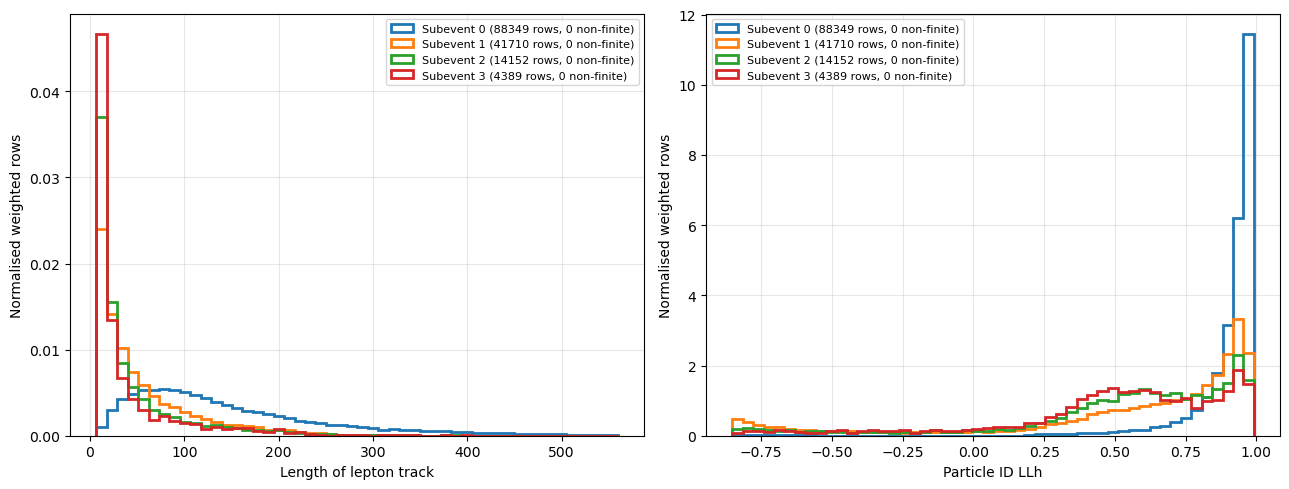

In [4]:
VARS = ["Length of lepton track", "Particle ID LLh"]
SUBEVENTS = [0, 1, 2, 3]

# Shared binning per variable, from the 0.5-99.5 percentile range of the preselected sample
bins = {}
for v in VARS:
    vals = pre[v].replace([np.inf, -np.inf], np.nan).dropna()
    lo, hi = np.percentile(vals, [0.5, 99.5])
    bins[v] = np.linspace(lo, hi, 51)

fig, axes = plt.subplots(1, len(VARS), figsize=(13, 5))
for i, s in enumerate(SUBEVENTS):
    sub = pre[pre["Subevent"] == s]
    for ax, v in zip(axes, VARS):
        finite = np.isfinite(sub[v])
        ax.hist(sub.loc[finite, v], bins=bins[v], weights=sub.loc[finite, WGT], density=True,
                histtype="step", lw=2, color=f"C{i}",
                label=f"Subevent {s} ({len(sub)} rows, {(~finite).sum()} non-finite)")
for ax, v in zip(axes, VARS):
    ax.set_xlabel(v)
    ax.set_ylabel("Normalised weighted rows")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

PID LLh vs ln(track length), one panel per sub-event: a random sample of 1000 rows from each (shared axes so the panels can be compared)


0 rows dropped (non-finite, or track length <= 0)


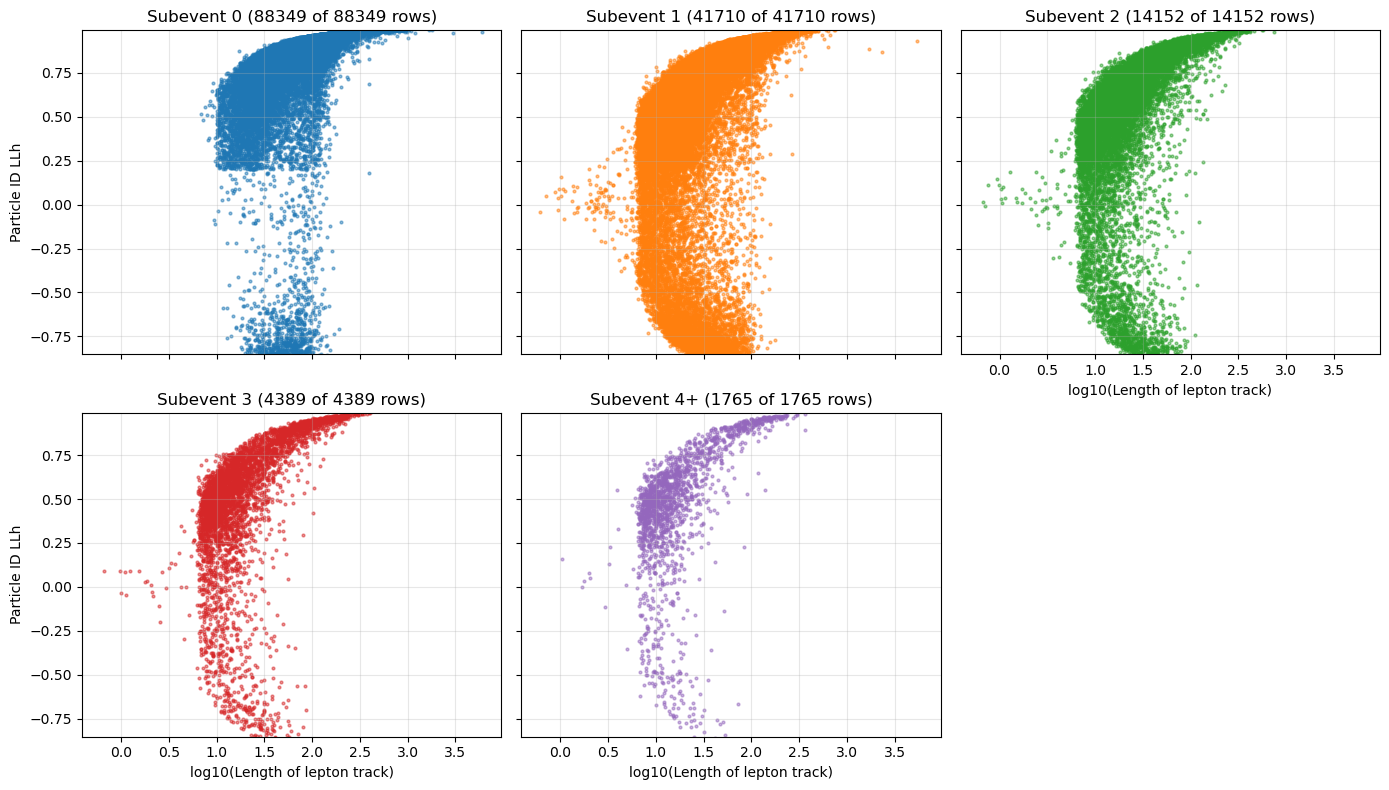

In [5]:
LEN, PID = "Length of lepton track", "Particle ID LLh"
N_SAMPLE = np.inf
ok = np.isfinite(pre[LEN]) & np.isfinite(pre[PID]) & (pre[LEN] > 0)   # ln needs a positive length
pts = pre[ok]
print(f"{(~ok).sum()} rows dropped (non-finite, or track length <= 0)")

groups = [(f"Subevent {s}", pts["Subevent"] == s) for s in SUBEVENTS] + [("Subevent 4+", pts["Subevent"] >= 4)]
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
axes = axes.ravel()
for i, (ax, (name, mask)) in enumerate(zip(axes, groups)):
    if mask.any():
        sample = pts[mask].sample(n=min(N_SAMPLE, mask.sum()), random_state=1)
        ax.scatter(np.log10(sample[LEN]), sample[PID], s=4, alpha=0.5, color=f"C{i}")
    ax.set_title(f"{name} ({min(N_SAMPLE, mask.sum())} of {mask.sum()} rows)")
    ax.grid(alpha=0.3)
for ax in axes[len(groups):]:
    ax.set_visible(False)
for ax in axes[::3]:
    ax.set_ylabel(PID)
for ax in axes[len(groups) - 3:len(groups)]:
    ax.set_xlabel(f"log10({LEN})")
    ax.xaxis.set_tick_params(labelbottom=True)
axes[0].set_ylim(bins[PID][0], bins[PID][-1])   # same 0.5-99.5 percentile range as the histograms
plt.tight_layout()
plt.show()